In [2]:
from google.colab import files
uploaded = files.upload()

Saving water_potability.csv to water_potability.csv


In [6]:
import pandas as pd

df = pd.read_csv("water_potability.csv")
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


In [8]:
df.describe()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000


In [9]:
df.columns

Index(['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity',
       'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability'],
      dtype='object')

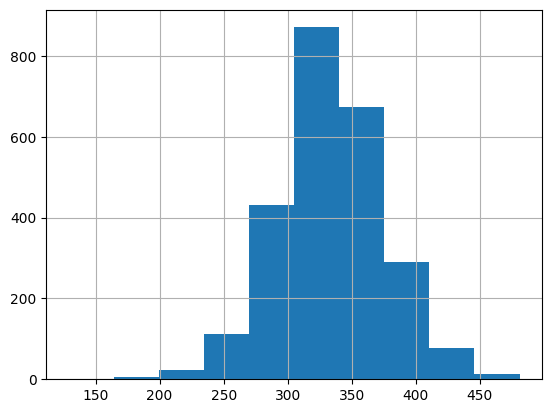

In [12]:
import matplotlib.pyplot as plt

df['Sulfate'].hist()
plt.show()

In [13]:
df.isnull().sum()

,0
ph,491
Hardness,0
Solids,0
Chloramines,0
Sulfate,781
Conductivity,0
Organic_carbon,0
Trihalomethanes,162
Turbidity,0
Potability,0


In [14]:
df = df.fillna(df.median())

In [15]:
X = df.drop('Potability', axis=1)
y = df['Potability']

In [16]:
print(X.head())
print(y.head())

         ph    Hardness        Solids  Chloramines     Sulfate  Conductivity  \
0  7.036752  204.890455  20791.318981     7.300212  368.516441    564.308654   
1  3.716080  129.422921  18630.057858     6.635246  333.073546    592.885359   
2  8.099124  224.236259  19909.541732     9.275884  333.073546    418.606213   
3  8.316766  214.373394  22018.417441     8.059332  356.886136    363.266516   
4  9.092223  181.101509  17978.986339     6.546600  310.135738    398.410813   

   Organic_carbon  Trihalomethanes  Turbidity  
0       10.379783        86.990970   2.963135  
1       15.180013        56.329076   4.500656  
2       16.868637        66.420093   3.055934  
3       18.436524       100.341674   4.628771  
4       11.558279        31.997993   4.075075  
0    0
1    0
2    0
3    0
4    0
Name: Potability, dtype: int64


In [17]:
df = df.fillna(df.median())

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [19]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000)

In [20]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.6280487804878049


In [21]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print(cm)

[[412   0]
 [244   0]]


In [22]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.63      1.00      0.77       412
           1       0.00      0.00      0.00       244

    accuracy                           0.63       656
   macro avg       0.31      0.50      0.39       656
weighted avg       0.39      0.63      0.48       656



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [23]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(class_weight='balanced', random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [24]:
y_pred = model.predict(X_test)

from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.68      0.88      0.77       412
           1       0.60      0.32      0.41       244

    accuracy                           0.67       656
   macro avg       0.64      0.60      0.59       656
weighted avg       0.65      0.67      0.64       656



In [25]:
import pandas as pd

importances = model.feature_importances_
feature_names = X.columns

feat_imp = pd.Series(importances, index=feature_names)
feat_imp = feat_imp.sort_values(ascending=False)

print(feat_imp)

ph                 0.126573
Hardness           0.119433
Sulfate            0.118845
Solids             0.116534
Chloramines        0.113808
Organic_carbon     0.104959
Conductivity       0.100986
Trihalomethanes    0.099957
Turbidity          0.098906
dtype: float64


In [26]:
y_prob = model.predict_proba(X_test)[:,1]

In [27]:
y_pred = (y_prob > 0.3).astype(int)

In [28]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.77      0.36      0.49       412
           1       0.43      0.82      0.56       244

    accuracy                           0.53       656
   macro avg       0.60      0.59      0.53       656
weighted avg       0.64      0.53      0.52       656



In [29]:
y_probs = model.predict_proba(X_test)[:, 1]

In [30]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_probs)

In [32]:
import numpy as np

optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_idx]

print("Best threshold:", optimal_threshold)

Best threshold: 0.41


In [33]:
y_pred_new = (y_probs >= optimal_threshold).astype(int)

In [34]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_new))

              precision    recall  f1-score   support

           0       0.74      0.68      0.71       412
           1       0.53      0.60      0.56       244

    accuracy                           0.65       656
   macro avg       0.63      0.64      0.64       656
weighted avg       0.66      0.65      0.65       656



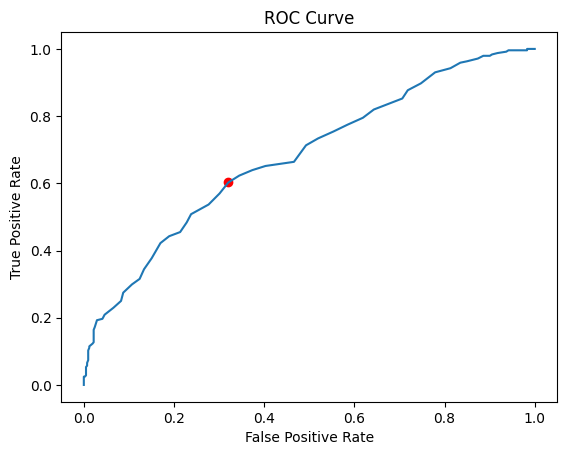

In [35]:
import matplotlib.pyplot as plt

plt.plot(fpr, tpr)
plt.scatter(fpr[optimal_idx], tpr[optimal_idx], color='red')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()

In [36]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds_pr = precision_recall_curve(y_test, y_probs)

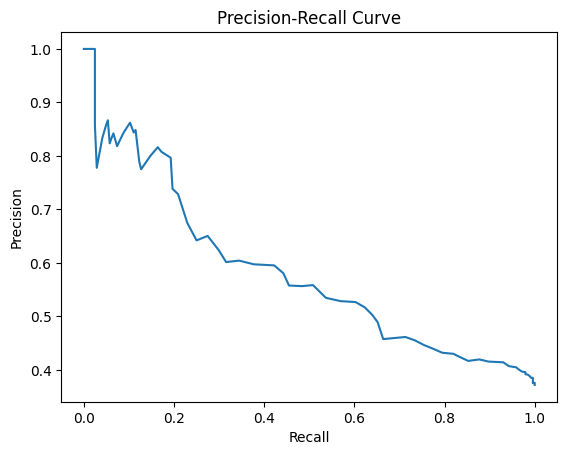

In [37]:
import matplotlib.pyplot as plt

plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.show()

In [38]:
precision >= 0.6

array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True])

In [39]:
import numpy as np

f1_scores = 2 * (precision * recall) / (precision + recall)
best_idx = np.argmax(f1_scores)

best_threshold_pr = thresholds_pr[best_idx]

print("Best threshold (PR):", best_threshold_pr)

Best threshold (PR): 0.26


In [40]:
best_threshold_pr = thresholds_pr[best_idx]

In [41]:
y_pred_pr = (y_probs >= best_threshold_pr).astype(int)

In [42]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_pr))

              precision    recall  f1-score   support

           0       0.84      0.22      0.35       412
           1       0.41      0.93      0.57       244

    accuracy                           0.48       656
   macro avg       0.63      0.58      0.46       656
weighted avg       0.68      0.48      0.43       656



In [43]:
for i in range(len(thresholds_pr)):
    if precision[i] >= 0.6:
        print(thresholds_pr[i], precision[i], recall[i])

0.5 0.60431654676259 0.3442622950819672
0.51 0.6015625 0.3155737704918033
0.52 0.6239316239316239 0.29918032786885246
0.53 0.6504854368932039 0.27459016393442626
0.54 0.6421052631578947 0.25
0.55 0.6746987951807228 0.22950819672131148
0.56 0.7285714285714285 0.20901639344262296
0.57 0.7384615384615385 0.19672131147540983
0.58 0.7966101694915254 0.19262295081967212
0.59 0.8076923076923077 0.1721311475409836
0.6 0.8163265306122449 0.16393442622950818
0.61 0.8 0.14754098360655737
0.62 0.775 0.12704918032786885
0.63 0.7894736842105263 0.12295081967213115
0.64 0.8484848484848485 0.11475409836065574
0.65 0.84375 0.11065573770491803
0.66 0.8620689655172413 0.10245901639344263
0.67 0.8461538461538461 0.09016393442622951
0.68 0.84 0.0860655737704918
0.7 0.8181818181818182 0.07377049180327869
0.71 0.8421052631578947 0.06557377049180328
0.72 0.8333333333333334 0.06147540983606557
0.74 0.8235294117647058 0.05737704918032787
0.75 0.8666666666666667 0.05327868852459016
0.76 0.8571428571428571 0.0491

In [53]:
y_pred_custom = (y_probs >= threshold_ales).astype(int)

In [54]:
print(classification_report(y_test, y_pred_custom))

              precision    recall  f1-score   support

           0       0.69      0.87      0.77       412
           1       0.60      0.34      0.44       244

    accuracy                           0.67       656
   macro avg       0.65      0.61      0.60       656
weighted avg       0.66      0.67      0.65       656

